In [1]:
import arviz as az
import bambi as bmb
import polars as  pl
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt

from kidney.contrasts import get_t_groups, get_overall_effects, get_gtyp_given_sex_age, get_sex_given_gtyp_age, get_mean
from kidney.paths import RESULTS_DIR_NEW, PREPARED_FILES_NEW, PLOT_DIR_NEW
from kidney.plotting import forestplot_oz, plot_ppc, set_symmetric_xlim
from kidney.sign_probs import get_sign_probs, get_signif

In [2]:
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.family'] = 'Arial'
az.rcParams["data.load"] = "eager"

In [3]:
idata_vehicle = az.from_netcdf(RESULTS_DIR_NEW / "idata_frequency_vehicle_change_double.nc")
idata_empa = az.from_netcdf(RESULTS_DIR_NEW / "idata_frequency_empa_change_double.nc")

In [4]:
print("Vehicle:")
display(az.summary(idata_vehicle, var_names=["~mu", "~1|rat", "~sigma"]))
print("Empa:")
display(az.summary(idata_empa, var_names=["~mu", "~1|rat", "~sigma"]))

Vehicle:


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,0.061,0.017,0.026,0.092,0.000,0.000,1952.0,1924.0,1.0
gtyp[fa/fa],-0.011,0.033,-0.071,0.052,0.001,0.001,2796.0,2078.0,1.0
age[Young],0.047,0.041,-0.027,0.122,0.001,0.001,2483.0,2632.0,1.0
sex[M],-0.050,0.038,-0.120,0.023,0.001,0.001,2331.0,2667.0,1.0
"gtyp:age[fa/fa, Young]",-0.026,0.052,-0.126,0.068,0.001,0.001,2437.0,2432.0,1.0
"gtyp:sex[fa/fa, M]",-0.016,0.051,-0.114,0.080,0.001,0.001,2625.0,2631.0,1.0
1|rat_sigma,0.028,0.014,0.003,0.054,0.000,0.000,1193.0,1096.0,1.0


Empa:


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,0.073,0.029,0.016,0.127,0.001,0.001,2369.0,2262.0,1.0
gtyp[fa/fa],-0.021,0.047,-0.107,0.071,0.001,0.001,2828.0,2314.0,1.0
age[Young],0.034,0.067,-0.096,0.155,0.001,0.001,3642.0,2830.0,1.0
sex[M],0.091,0.049,-0.010,0.178,0.001,0.001,2719.0,2274.0,1.0
"gtyp:age[fa/fa, Young]",0.018,0.080,-0.137,0.166,0.001,0.001,3335.0,2543.0,1.0
"gtyp:sex[fa/fa, M]",-0.178,0.078,-0.325,-0.031,0.001,0.001,2894.0,2640.0,1.0
1|rat_sigma,0.043,0.019,0.004,0.077,0.001,0.000,1223.0,996.0,1.0


In [5]:
msts_vehicle = pl.read_csv(PREPARED_FILES_NEW["frequency_vehicle_double"])
msts_empa = pl.read_csv(PREPARED_FILES_NEW["frequency_empa_double"])

## Posterior predictive checks

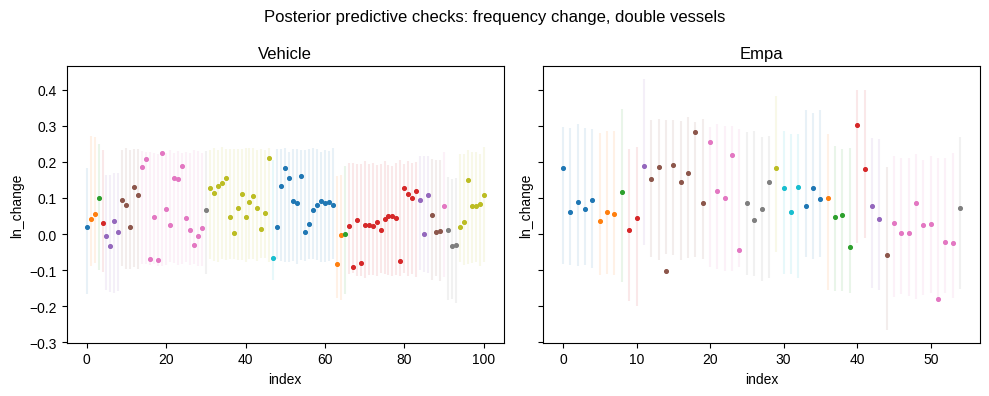

In [6]:
PLOT_DIR_NEW.mkdir(parents=True, exist_ok=True)
f, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, idata, name, msts in zip(
    axes,
    (idata_vehicle, idata_empa),
    ("vehicle", "empa"),
    (msts_vehicle, msts_empa),
):
    ax = plot_ppc(ax, idata, msts, ycol="ln_change", groupcol="rat")
    ax.set_title(name.capitalize())
    legend = ax.get_legend()
    if legend is not None:
        legend.remove()

f.suptitle("Posterior predictive checks: frequency change, double vessels")
f.tight_layout()
f.savefig(PLOT_DIR_NEW / "ppc_frequency_change-double.png", bbox_inches="tight", dpi=200)

Each dot is a vessel, sorted by rat; lines are 1%–99% posterior predictive intervals. The dataset now contains only double vessels, so there is no activity-type-specific subdivision.

## Effects

The model is `ln_change ~ (1|rat) + gtyp + age + sex + gtyp:age + gtyp:sex`, with a single residual standard deviation. Contrasts follow the brief. The overall effect of a factor is averaged with equal weights over the levels of the other factors, e.g. the overall gtyp effect is the mean of fa/fa − fa/+ over the four age/sex groups. The gtyp effect given sex is averaged over age, and vice versa. SP is the posterior probability that the contrast is positive; lines are 95% intervals.
The combined plot replaces the overall sex effect with male − female contrasts within `fa/fa` and `fa/+`, averaged over age. Sex-given-age contrasts are excluded.

In [7]:
def plot_effects(ts_vehicle, ts_empa, figsize):
    f, axes = plt.subplots(1, 2, figsize=figsize)
    for ax, ts, tle in zip(axes, (ts_vehicle, ts_empa), ("Vehicle", "Empa")):
        ax = forestplot_oz(ax, ts, xlabel="Test statistic\n(frequency change)", sign_probs=True)
        set_symmetric_xlim(ax, ts, pad=1.8)
        ax.set_title(tle)
        ax.spines[['top', 'right', 'left']].set_visible(False)
    axes[1].set_yticks([], [])
    return f, axes


t_groups_vehicle, t_groups_empa = (get_t_groups(idata) for idata in (idata_vehicle, idata_empa))
overall_ts_vehicle, overall_ts_empa = (
    get_overall_effects(t_groups)
    for t_groups in (t_groups_vehicle, t_groups_empa)
)
gtyp_ts_vehicle, gtyp_ts_empa = (get_gtyp_given_sex_age(t_groups) for t_groups in (t_groups_vehicle, t_groups_empa))
sex_ts_vehicle, sex_ts_empa = (
    get_sex_given_gtyp_age(t_groups)
    for t_groups in (t_groups_vehicle, t_groups_empa)
)

# Replace the overall sex contrast with sex effects within each genotype.
# Exclude the sex-given-age contrasts.
plot_ts_vehicle = {
    **{k: v for k, v in overall_ts_vehicle.items() if k != "male - female"},
    **{k: v for k, v in sex_ts_vehicle.items() if k in ("male - female, fa/fa", "male - female, fa/+")},
}
plot_ts_empa = {
    **{k: v for k, v in overall_ts_empa.items() if k != "male - female"},
    **{k: v for k, v in sex_ts_empa.items() if k in ("male - female, fa/fa", "male - female, fa/+")},
}

### Overall genotype and age effects; sex effects given genotype

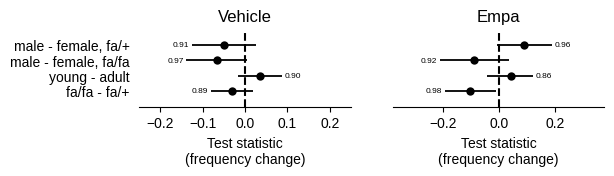

In [8]:
f, axes = plot_effects(plot_ts_vehicle, plot_ts_empa, figsize=(6, 1))
f.savefig(PLOT_DIR_NEW / "ts_frequency_change_overall_and_sg-double.pdf", bbox_inches="tight", dpi=200)

### Effect of gtyp given sex and given age

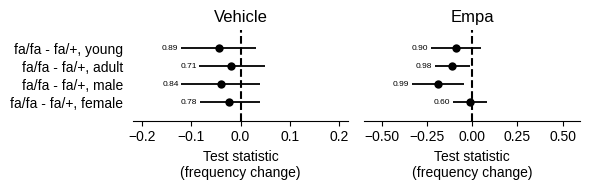

In [9]:
f, axes = plot_effects(gtyp_ts_vehicle, gtyp_ts_empa, figsize=(6, 2))
f.tight_layout()
# f.savefig(PLOT_DIR_NEW / "ts_frequency_change_gtyp_given_sex_age-double.png", bbox_inches="tight", dpi=200)

### Mean change

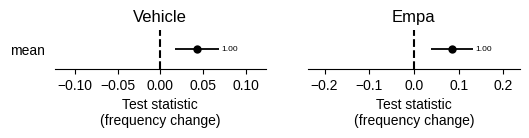

In [10]:
mean_ts_vehicle, mean_ts_empa = (
    {"mean": get_mean(idata)} for idata in (idata_vehicle, idata_empa)
)
f, axes = plot_effects(mean_ts_vehicle, mean_ts_empa, figsize=(6, 0.5))
f.savefig(PLOT_DIR_NEW / "ts_frequency_change_mean-double.pdf", bbox_inches="tight", dpi=200)

## Show sign probabilities in tables

In [11]:
sp_all = pd.concat(
    objs=[
        pd.DataFrame({
            "vehicle": get_sign_probs(ts_vehicle),
            "vehicle_signif": {k: get_signif(v) for k, v in get_sign_probs(ts_vehicle).items()},
            "empa": get_sign_probs(ts_empa),
            "empa_signif": {k: get_signif(v) for k, v in get_sign_probs(ts_empa).items()},
        })
        for ts_vehicle, ts_empa in (
            (plot_ts_vehicle, plot_ts_empa),
            (gtyp_ts_vehicle, gtyp_ts_empa),
            (mean_ts_vehicle, mean_ts_empa),
        )
    ],
    keys=("overall + sex given gtyp", "gtyp given sex/age", "mean"),
    names=("contrast", "group"),
)
sp_all

vehicle vehicle_signif  \
contrast                 group                                          
overall + sex given gtyp fa/fa - fa/+          0.89350                  
                         young - adult         0.90375                  
                         male - female, fa/fa  0.96575                  
                         male - female, fa/+   0.90675                  
gtyp given sex/age       fa/fa - fa/+, female  0.78275                  
                         fa/fa - fa/+, male    0.83950                  
                         fa/fa - fa/+, adult   0.71450                  
                         fa/fa - fa/+, young   0.88550                  
mean                     mean                  0.99925              *   

                                                  empa empa_signif  
contrast                 group                                      
overall + sex given gtyp fa/fa - fa/+          0.98100           *  
                         young - adult         0.86300              
                         male - female, fa/fa  0.92300              
                         male - female, fa/+   0.96475              
gtyp given sex/age       fa/fa - fa/+, female  0.59975              
                         fa/fa - fa/+, male    0.99475           *  
                         fa/fa - fa/+, adult   0.98300           *  
                         fa/fa - fa/+, young   0.90425              
mean                     mean                  0.99925           *